# Análisis exploratorio: ¿quién, qué, cuándo y dónde se pierde la partida?

**Visualización de datos y narración de historias** · Héctor Manuel Morán Maldonado

**Proyecto:** *¿En qué minuto se perdió la partida?* — análisis de mis partidas clasificatorias
de League of Legends.

El proyecto respondió tres hipótesis **registradas antes de ver los datos** (H1–H3). Este notebook
es **exploratorio**: hace preguntas nuevas que surgieron al cerrar el proyecto, y sus resultados
no son confirmaciones, sino pistas para una siguiente ronda. Las cuatro preguntas:

1. **¿Perdí yo la partida?** Mi oro contra el de mi rival directo de línea, y cuánto del déficit del
   equipo viene de mi línea.
2. **¿Qué pasa en el quiebre?** Cuánto mueve el oro cada tipo de evento, y qué eventos sobran o
   faltan alrededor del minuto en que la partida se quiebra.
3. **¿Importa el camino o solo dónde vas?** Si saber *cómo* llegó la ventaja al minuto $t$ ayuda a
   predecir el resultado más que saber solo la ventaja en $t$; y la probabilidad de ganar por
   minuto y ventaja.
4. **¿Dónde muero?** Mis muertes sobre el mapa, en victorias y derrotas, antes y después del
   minuto 15.

**Datos y privacidad.** A diferencia del resto del repositorio, este notebook usa las tablas **por
participante** (`LoL_Datos/anonimizado/cuadros.csv`, `eventos.csv`, `participantes.csv`), que
**no se publican**: traen el campeón y el rol de cada desconocido. Por eso **no se puede volver a
ejecutar desde el repositorio público**; lo publicado son solo sus salidas, que son agregados
(conteos, tasas, curvas y mapas de densidad). El script que lo construye revisa, antes de guardar,
que ninguna salida contenga el identificador de una partida o de un jugador ni el campeón de otro
jugador.

## 0. Definiciones (fijadas antes de ver los resultados)

Se reutilizan las del proyecto: el mismo embudo (**1,195 partidas**), la medida
$v(t) = \frac{\text{oro propio} - \text{oro rival}}{\text{oro total}} \times 100$, el quiebre **D2**
(último cruce de $v$ hacia abajo) y la convención de minutos de E2–E4: un evento con marca de tiempo
`ms` cae en el minuto $m = \lfloor ms / 60000 \rfloor$ y ocurre entre los cuadros $m$ y $m+1$.

**1 · ¿Perdí yo?**
- *Rival directo:* el jugador del otro equipo con mi mismo rol. Se excluyen las partidas donde algún
  equipo no tiene sus cinco roles distintos.
- *Diferencia de línea:* oro de un rol de mi equipo menos el oro del mismo rol rival. Las cinco
  diferencias suman exactamente la diferencia de oro del equipo (se comprueba en el código).
- Como 7 de cada 10 partidas las jugué de **BOTTOM**, la descomposición por roles se hace solo en
  esas partidas; la comparación con el resultado se separa por rol (MIDDLE, con 16 partidas, no se
  reporta aparte).
- *Antes del quiebre:* el estado de cada duelo en el cuadro $D2 - 1$. Se dejan fuera los quiebres
  anteriores al minuto 5, donde casi todos los duelos siguen empatados. (Este corte se agregó al ver
  la primera versión de la tabla, que estaba dominada por empates.)

**2 · El quiebre.**
- *Valor de un evento:* regresión lineal de $\Delta v(t) = v(t) - v(t-1)$ sobre el número de
  eventos de cada tipo en el minuto $t-1$, a favor y en contra, por separado para los minutos 1–15 y
  16 en adelante. Intervalos con *bootstrap* remuestreando **partidas** (1,000 réplicas).
- *Ventana del quiebre:* la de E3, minutos $[D2-2,\ D2+1)$. Se compara lo observado en la ventana con
  lo **esperado para esos mismos minutos** en las derrotas (tasa por minuto de todas las derrotas
  que seguían en juego, fuera de su propia ventana). Razón observado / esperado con *bootstrap* por
  partida. H2 ya probó "un monstruo épico del rival a ±1 minuto" (no concluyente): aquí no se vuelve
  a probar, se mira la **composición** completa.

**3 · Camino contra posición.** Para cada minuto $t$, con las partidas que siguen en juego después
de $t$, se predice el resultado con: **M0** (nada: la proporción de victorias), **M1** ($v(t)$),
**M2** ($v(t)$ y el cambio de los últimos 3 minutos) y **M3** (toda la curva $v(0..t)$, regresión
logística con penalización elegida por validación cruzada interna). Se comparan con la **pérdida
logarítmica** fuera de muestra (validación cruzada de 5 pliegues); la exactitud no distingue
diferencias pequeñas.

**4 · Dónde muero.** Mis muertes (`CHAMPION_KILL` con víctima = yo). Las partidas del lado rojo se
reflejan por el centro del mapa para que **mi base quede siempre abajo a la izquierda**. Las
densidades se dividen entre los **minutos jugados** de cada grupo. El mapa es un esquema dibujado
(no la imagen oficial).

In [1]:
import pathlib, sys, time, warnings

import numpy as np
import pandas as pd

RAIZ = pathlib.Path.cwd().parent              # el notebook vive en LoL_Exploratorio/
sys.path.insert(0, str(RAIZ / "LoL_Analisis" / "scripts"))
import e1_quiebre as e1                        # embudo, v(t), quiebres, paleta, wilson
import e2_e4 as e24                            # objetivos públicos con la convención de E2-E4

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
%matplotlib inline
warnings.filterwarnings("ignore", category=FutureWarning)
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.model_selection import StratifiedKFold

SEMILLA = 20261010
PRIVADO = RAIZ / "LoL_Datos" / "anonimizado"
AZUL, NARANJA, TINTA, SUAVE = e1.AZUL, e1.NARANJA, e1.TINTA, e1.SUAVE
COL_RES = {"Victoria": AZUL, "Derrota": NARANJA}
plt.rcParams.update({"font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})

In [2]:
partidas = pd.read_csv(e1.PUBLICO / "partidas.csv", dtype={"parche": str})
muestra, _ = e1.filtrar(partidas)
ids = set(muestra["partida"])
v = e1.medida_v(pd.read_csv(e1.PUBLICO / "oro_equipo.csv"), muestra)
q = e1.quiebres(v).set_index("partida")           # D2 y último cuadro de cada partida
v["v"] *= 100                                     # en % del oro total
gane = muestra.set_index("partida")["gane"]
lado = muestra.set_index("partida")["equipoPropio"]

part = pd.read_csv(PRIVADO / "participantes.csv",
                   usecols=["partida", "participantId", "es_propio", "teamId", "rol"])
part = part[part["partida"].isin(ids)]
yo = part[part["es_propio"] == 1].set_index("partida")[["participantId", "teamId", "rol"]]
cuadros = pd.read_csv(PRIVADO / "cuadros.csv",
                      usecols=["partida", "minuto", "participantId", "teamId", "oroTotal"])
cuadros = cuadros[cuadros["partida"].isin(ids)]
ev = pd.read_csv(PRIVADO / "eventos.csv",
                 usecols=["partida", "tipo", "ms", "equipoAutor", "equipoVictima", "victimId",
                          "monsterType", "x", "y"])
ev = ev[ev["partida"].isin(ids) & ev["tipo"].isin(
    ["CHAMPION_KILL", "BUILDING_KILL", "ELITE_MONSTER_KILL", "TURRET_PLATE_DESTROYED"])].copy()
ev["minuto"] = ev["ms"] // 60000

print(f"Partidas: {len(muestra):,} ({int(gane.sum())} victorias, {int((1 - gane).sum())} derrotas)")
print("Mi rol:", yo["rol"].value_counts().to_dict())

Partidas: 1,195 (658 victorias, 537 derrotas)
Mi rol: {'BOTTOM': 839, 'UTILITY': 153, 'JUNGLE': 127, 'TOP': 61, 'MIDDLE': 15}


## 1. ¿Perdí yo la partida?

Cada partida enfrenta cinco duelos de rol contra rol. Si se resta, para cada rol, el oro del
jugador de mi equipo menos el de su rival directo, las cinco diferencias suman la diferencia de oro
del equipo. Eso permite preguntar **qué parte del déficit viene de mi línea**.

In [3]:
roles_ok = part.groupby(["partida", "teamId"])["rol"].nunique().eq(5).groupby("partida").all()
validas = roles_ok[roles_ok].index
c = cuadros[cuadros["partida"].isin(validas)].merge(
    part[["partida", "participantId", "rol"]], on=["partida", "participantId"])
c["lado"] = np.where(c["teamId"] == c["partida"].map(lado), "propio", "rival")
oro_rol = c.pivot_table(index=["partida", "minuto", "rol"], columns="lado",
                        values="oroTotal", aggfunc="sum")
dif_rol = (oro_rol["propio"] - oro_rol["rival"]).unstack("rol")      # partida·minuto × rol

# Comprobación: las cinco diferencias suman la diferencia de oro del equipo.
equipo = v.set_index(["partida", "minuto"]).loc[dif_rol.index]
assert np.array_equal(dif_rol.sum(axis=1).to_numpy(),
                      (equipo["oroPropio"] - equipo["oroRival"]).to_numpy())

ROLES = ["TOP", "JUNGLE", "MIDDLE", "BOTTOM", "UTILITY"]
mi_rol = yo["rol"].reindex(dif_rol.index.get_level_values("partida")).to_numpy()
columna = pd.Index(ROLES).get_indexer(mi_rol)
assert (columna >= 0).all(), "partida con un rol propio fuera de los cinco"
dif_rol["mia"] = dif_rol[ROLES].to_numpy()[np.arange(len(dif_rol)), columna]
dif_rol["equipo"] = dif_rol[ROLES].sum(axis=1)
dif_rol["gane"] = dif_rol.index.get_level_values("partida").map(gane).to_numpy()
dif_rol["mi_rol"] = mi_rol
print(f"Partidas con los cinco roles en ambos equipos: {len(validas):,} de {len(muestra):,}")
print("Comprobación: la suma de las cinco diferencias de rol = diferencia de oro del equipo, "
      "en todos los cuadros.")

Partidas con los cinco roles en ambos equipos: 1,194 de 1,195
Comprobación: la suma de las cinco diferencias de rol = diferencia de oro del equipo, en todos los cuadros.


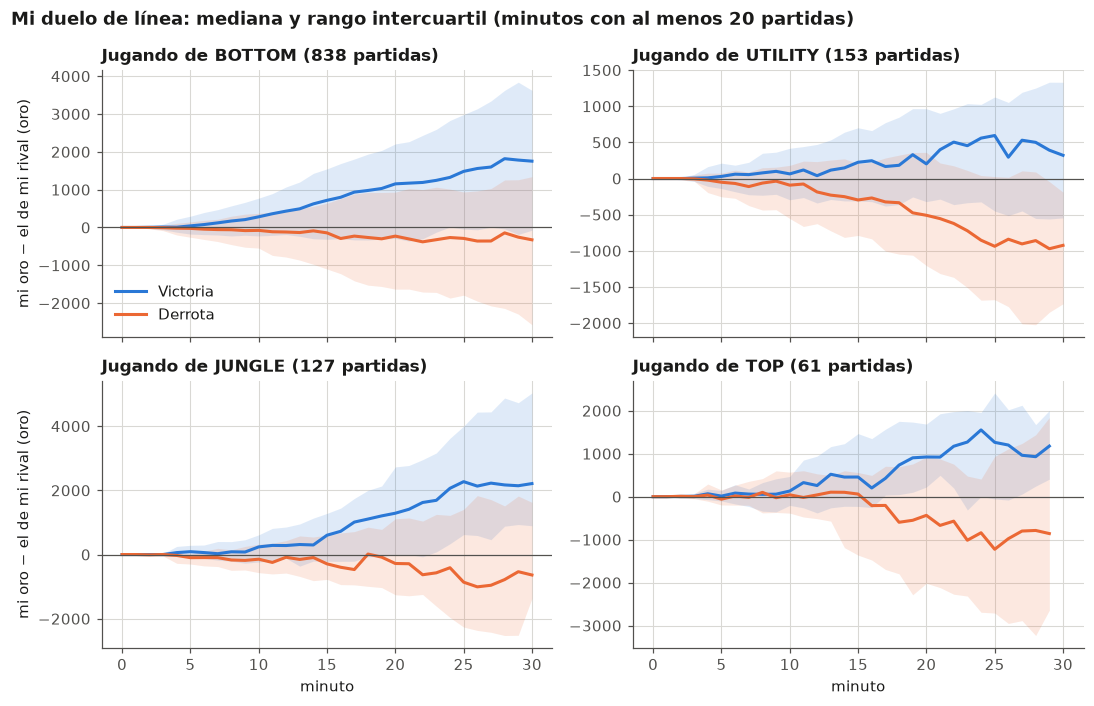

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.5), sharex=True)
for ax, rol in zip(axes.ravel(), ["BOTTOM", "UTILITY", "JUNGLE", "TOP"]):
    sub = dif_rol[dif_rol["mi_rol"] == rol]
    n_part = sub.index.get_level_values("partida").nunique()
    for g, (nombre, color) in zip((1, 0), COL_RES.items()):
        s = sub[sub["gane"] == g]["mia"].groupby("minuto")
        cuantos = s.size()
        qs = s.quantile([.25, .5, .75]).unstack()[cuantos >= 20].loc[:30]
        ax.fill_between(qs.index, qs[.25], qs[.75], color=color, alpha=.15, lw=0)
        ax.plot(qs.index, qs[.5], color=color, label=nombre)
    ax.axhline(0, color=SUAVE, lw=.8)
    ax.set_title(f"Jugando de {rol} ({n_part} partidas)")
for ax in axes[1]:
    ax.set_xlabel("minuto")
for ax in axes[:, 0]:
    ax.set_ylabel("mi oro − el de mi rival (oro)")
axes[0, 0].legend(loc="lower left")
fig.suptitle("Mi duelo de línea: mediana y rango intercuartil (minutos con al menos 20 partidas)",
             x=.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

In [5]:
def tasa(k, n):
    lo, hi = e1.wilson(int(k), int(n))
    return f"{k / n:.0%} [{lo:.0%}–{hi:.0%}] (n={n})" if n else "—"

filas = []
for t in (10, 15, 20):
    en_t = dif_rol.xs(t, level="minuto")
    for rol in ["BOTTOM", "UTILITY", "JUNGLE", "TOP", "todos"]:
        s = en_t if rol == "todos" else en_t[en_t["mi_rol"] == rol]
        arriba, abajo = s[s["mia"] > 0], s[s["mia"] < 0]
        eq_arriba = s[s["equipo"] > 0]
        filas.append({"minuto": t, "mi rol": rol,
                      "gano si mi línea va arriba": tasa(arriba["gane"].sum(), len(arriba)),
                      "gano si mi línea va abajo": tasa(abajo["gane"].sum(), len(abajo)),
                      "gano si el equipo va arriba": tasa(eq_arriba["gane"].sum(), len(eq_arriba))})
pd.DataFrame(filas).set_index(["minuto", "mi rol"])

gano si mi línea va arriba gano si mi línea va abajo  \
minuto mi rol                                                         
10     BOTTOM       64% [60%–68%] (n=466)     47% [42%–52%] (n=372)   
       UTILITY       55% [44%–66%] (n=74)      43% [33%–54%] (n=79)   
       JUNGLE        69% [57%–78%] (n=67)      42% [30%–54%] (n=60)   
       TOP           57% [41%–71%] (n=37)      50% [31%–69%] (n=24)   
       todos        63% [59%–67%] (n=655)     46% [41%–50%] (n=539)   
15     BOTTOM       67% [62%–71%] (n=485)     43% [38%–48%] (n=347)   
       UTILITY       61% [49%–71%] (n=74)      38% [28%–50%] (n=78)   
       JUNGLE        68% [57%–77%] (n=75)      39% [27%–53%] (n=51)   
       TOP           61% [45%–74%] (n=38)      43% [26%–63%] (n=23)   
       todos        66% [62%–69%] (n=682)     41% [37%–46%] (n=504)   
20     BOTTOM       69% [64%–73%] (n=477)     40% [35%–46%] (n=314)   
       UTILITY       62% [50%–72%] (n=68)      35% [25%–46%] (n=75)   
       JUNGLE        69% [58%–78%] (n=74)      38% [26%–52%] (n=50)   
       TOP           69% [54%–81%] (n=39)      32% [15%–54%] (n=19)   
       todos        68% [64%–71%] (n=668)     38% [34%–43%] (n=463)   

               gano si el equipo va arriba  
minuto mi rol                               
10     BOTTOM        73% [69%–77%] (n=449)  
       UTILITY        66% [55%–75%] (n=82)  
       JUNGLE         64% [52%–75%] (n=59)  
       TOP            82% [61%–93%] (n=22)  
       todos         72% [68%–75%] (n=620)  
15     BOTTOM        77% [73%–81%] (n=457)  
       UTILITY        71% [61%–79%] (n=86)  
       JUNGLE         73% [61%–82%] (n=63)  
       TOP            77% [60%–89%] (n=31)  
       todos         76% [72%–79%] (n=644)  
20     BOTTOM        80% [76%–84%] (n=436)  
       UTILITY        75% [65%–83%] (n=81)  
       JUNGLE         79% [67%–87%] (n=62)  
       TOP            90% [75%–97%] (n=31)  
       todos         80% [76%–83%] (n=617)

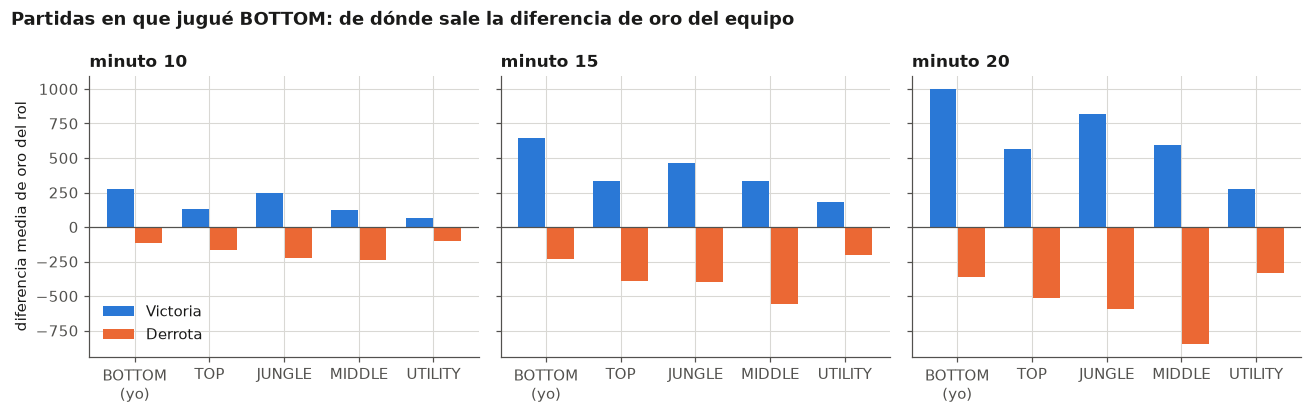

partidas  diferencia del equipo (oro) parte BOTTOM  \
minuto resultado                                                       
10     Victoria        473                          850          33%   
       Derrota         365                         -841          13%   
15     Victoria        471                         1967          33%   
       Derrota         361                        -1776          13%   
20     Victoria        453                         3259          31%   
       Derrota         338                        -2646          14%   

                 parte TOP parte JUNGLE parte MIDDLE parte UTILITY  
minuto resultado                                                    
10     Victoria        16%          29%          15%            8%  
       Derrota         20%          26%          28%           12%  
15     Victoria        17%          24%          17%            9%  
       Derrota         22%          22%          31%           11%  
20     Victoria        17%          25%          18%            9%  
       Derrota         19%          22%          32%           13%

In [6]:
bot = dif_rol[dif_rol["mi_rol"] == "BOTTOM"]
categorias = ["BOTTOM", "TOP", "JUNGLE", "MIDDLE", "UTILITY"]
etiquetas = ["BOTTOM\n(yo)", "TOP", "JUNGLE", "MIDDLE", "UTILITY"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
filas = []
for ax, t in zip(axes, (10, 15, 20)):
    en_t = bot.xs(t, level="minuto")
    x = np.arange(len(categorias))
    for j, (g, (nombre, color)) in enumerate(zip((1, 0), COL_RES.items())):
        medias = en_t[en_t["gane"] == g][categorias].mean()
        ax.bar(x + (j - .5) * .38, medias, width=.36, color=color, label=nombre)
        parte = medias / medias.sum()
        filas.append({"minuto": t, "resultado": nombre, "partidas": int((en_t["gane"] == g).sum()),
                      "diferencia del equipo (oro)": round(medias.sum()),
                      **{f"parte {r}": f"{p:.0%}" for r, p in parte.items()}})
    ax.axhline(0, color=SUAVE, lw=.8)
    ax.set_xticks(x, etiquetas)
    ax.set_title(f"minuto {t}")
axes[0].set_ylabel("diferencia media de oro del rol")
axes[0].legend(loc="lower left")
fig.suptitle("Partidas en que jugué BOTTOM: de dónde sale la diferencia de oro del equipo",
             x=.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()
pd.DataFrame(filas).set_index(["minuto", "resultado"])

In [7]:
# Justo antes del quiebre (cuadro D2 − 1): ¿qué roles ya iban abajo en su duelo?
# Solo quiebres del minuto 5 en adelante: antes, casi todos los duelos siguen empatados en 0.
perd = q[(q["gane"] == 0) & q["d2"].notna()]
filas, tempranos = [], 0
for pid, d2 in perd["d2"].astype(int).items():
    if (pid, d2 - 1) in bot.index:
        if d2 < 5:
            tempranos += 1
            continue
        filas.append(bot.loc[(pid, d2 - 1), categorias])
antes = pd.DataFrame(filas)
abajo = (antes < 0)
resumen_q = pd.DataFrame({
    "va arriba": (antes > 0).mean().map("{:.0%}".format),
    "empatado": (antes == 0).mean().map("{:.0%}".format),
    "va abajo": abajo.mean().map("{:.0%}".format),
    "abajo, intervalo 95 %": [f"{e1.wilson(int(k), len(abajo))[0]:.0%}–{e1.wilson(int(k), len(abajo))[1]:.0%}"
                              for k in abajo.sum()],
    "diferencia mediana (oro)": antes.median().round(0).astype(int),
}, index=categorias).rename(index={"BOTTOM": "BOTTOM (yo)"})
print(f"Derrotas jugando BOTTOM con quiebre D2: {len(antes) + tempranos}; se dejan fuera {tempranos} "
      f"con quiebre antes del minuto 5. Estado de cada duelo un minuto antes del quiebre, en las "
      f"{len(antes)} restantes:")
resumen_q

Derrotas jugando BOTTOM con quiebre D2: 363; se dejan fuera 116 con quiebre antes del minuto 5. Estado de cada duelo un minuto antes del quiebre, en las 247 restantes:


,va arriba,empatado,va abajo,"abajo, intervalo 95 %",diferencia mediana (oro)
BOTTOM (yo),60%,0%,40%,35%–47%,255
TOP,54%,0%,46%,40%–52%,124
JUNGLE,56%,0%,44%,38%–50%,115
MIDDLE,48%,0%,52%,46%–58%,-32
UTILITY,54%,0%,46%,40%–52%,37


**Lectura · ¿perdí yo?**

- **Mi línea casi nunca se derrumba en las derrotas.** Jugando BOTTOM, la mediana de mi duelo en las
  derrotas se queda entre 0 y −400 de oro hasta el minuto 30, mientras que en las victorias crece
  hasta +1,800. Lo que separa las victorias de las derrotas en mi línea es *cuánto gano*, no *cuánto
  pierdo*.
- **Ir arriba en mi línea ayuda, pero menos que ir arriba como equipo.** Al minuto 15, jugando BOTTOM,
  gano el 67 % de las partidas en que voy arriba en mi duelo y el 43 % en que voy abajo; si el que va
  arriba es el **equipo**, gano el 77 %. Lo mismo en los otros roles, con intervalos más anchos.
- **En las derrotas, el déficit viene sobre todo de otras líneas.** Al minuto 15 de mis derrotas
  jugando BOTTOM, el equipo va 1,776 de oro abajo y mi línea aporta solo el **13 %** de ese déficit;
  MIDDLE aporta el **31 %**. En las victorias, mi línea aporta el 33 % de la ventaja. Como cada rol
  junta oro a un ritmo distinto, la comparación justa es la de cada rol consigo mismo: BOTTOM pasa
  del 33 % de la ventaja al 13 % del déficit, y MIDDLE del 17 % al 31 %.
- **Justo antes del quiebre** (247 derrotas con quiebre del minuto 5 en adelante), mi duelo es el
  que **menos** veces va abajo: 40 % [35–47 %], con una diferencia mediana de **+255** de oro a mi
  favor. Los demás roles van abajo entre el 44 % y el 46 % de las veces, y MIDDLE el 52 % [46–58 %].
  Solo con MIDDLE los intervalos apenas se tocan; con los demás se traslapan.

**Respuesta exploratoria:** en general, *no* pierdo yo la partida en mi línea. Ojo: yo soy el mismo
jugador en todas las partidas y mis compañeros cambian; además, mi duelo mide solo mi oro contra el
de mi rival directo, no lo que hago fuera de mi línea.

## 2. ¿Qué pasa en el quiebre?

Primero, **cuánto oro mueve cada tipo de evento**, en promedio, en el minuto en que ocurre. Después,
qué eventos aparecen **más o menos de lo esperado** alrededor del quiebre de las derrotas.

In [8]:
def lado_de(partida_col, equipo_col):
    '''"propio" / "rival" según el equipo del evento y mi equipo en esa partida.'''
    return np.where(equipo_col == partida_col.map(lado), "propio", "rival")

k = ev[ev["tipo"] == "CHAMPION_KILL"]
muertes = pd.DataFrame({"partida": k["partida"], "minuto": k["minuto"],
                        "clase": np.where(lado_de(k["partida"], k["equipoVictima"]) == "propio",
                                          "muerte|en contra", "muerte|a favor")})
NOMBRE_OBJ = {"DRAGON": "dragón", "HORDE": "larvas", "RIFTHERALD": "heraldo",
              "BARON_NASHOR": "barón", "ATAKHAN": "Atakhan"}
o = ev[ev["tipo"].isin(["BUILDING_KILL", "TURRET_PLATE_DESTROYED", "ELITE_MONSTER_KILL"])
       & ev["equipoAutor"].isin([100, 200])]
tipo_o = np.select([o["tipo"] == "BUILDING_KILL", o["tipo"] == "TURRET_PLATE_DESTROYED"],
                   ["estructura", "placa"], o["monsterType"].map(NOMBRE_OBJ).fillna("otro"))
objetivos = pd.DataFrame({"partida": o["partida"], "minuto": o["minuto"],
                          "clase": pd.Series(tipo_o, index=o.index) + "|" + np.where(
                              lado_de(o["partida"], o["equipoAutor"]) == "propio",
                              "a favor", "en contra")})
todos_ev = pd.concat([muertes, objetivos[~objetivos["clase"].str.startswith("otro")]])
conteo = todos_ev.groupby(["partida", "minuto", "clase"]).size().unstack(fill_value=0)

# Una fila por partida y minuto t ≥ 1: Δv(t) y los eventos del minuto t − 1.
dv = v[["partida", "minuto", "v"]].copy()
dv["dv"] = dv.groupby("partida")["v"].diff()
dv = dv.dropna()
dv["m_ev"] = dv["minuto"] - 1
datos = dv.merge(conteo, left_on=["partida", "m_ev"], right_index=True, how="left").fillna(0)
CLASES = sorted(conteo.columns)
print(f"{len(datos):,} minutos de {datos['partida'].nunique():,} partidas; "
      f"{int(datos[CLASES].to_numpy().sum()):,} eventos")

37,081 minutos de 1,195 partidas; 127,345 eventos


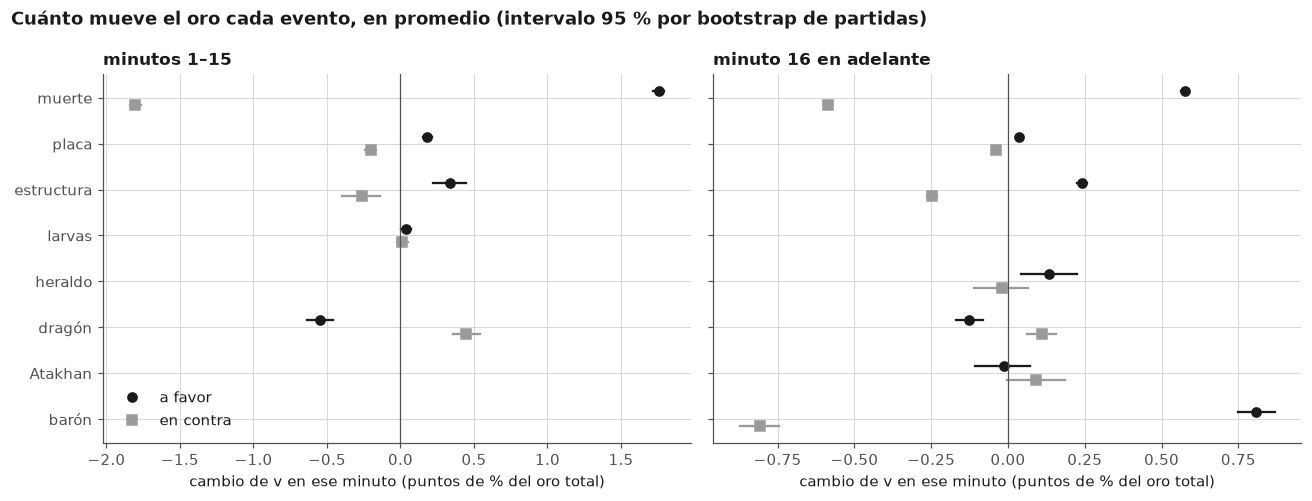

,minutos 1–15,minuto 16 en adelante
evento (— = menos de 30 casos),,
Atakhan · a favor,—,"-0.01 [-0.11, +0.07]"
Atakhan · en contra,—,"+0.09 [-0.00, +0.19]"
barón · a favor,—,"+0.81 [+0.75, +0.87]"
barón · en contra,—,"-0.81 [-0.87, -0.75]"
dragón · a favor,"-0.55 [-0.64, -0.46]","-0.13 [-0.17, -0.08]"
dragón · en contra,"+0.45 [+0.35, +0.54]","+0.11 [+0.06, +0.16]"
estructura · a favor,"+0.33 [+0.22, +0.45]","+0.24 [+0.22, +0.26]"
estructura · en contra,"-0.26 [-0.40, -0.14]","-0.25 [-0.26, -0.23]"
heraldo · a favor,—,"+0.13 [+0.04, +0.22]"


In [9]:
def ajustar(d):
    A = np.column_stack([np.ones(len(d)), d[CLASES].to_numpy()])
    return np.linalg.lstsq(A, d["dv"].to_numpy(), rcond=None)[0][1:]

def con_bootstrap(d, B=1000):
    rng = np.random.default_rng(SEMILLA)
    grupos = d.groupby("partida").indices
    llaves = list(grupos)
    A = np.column_stack([np.ones(len(d)), d[CLASES].to_numpy()])
    y = d["dv"].to_numpy()
    reps = []
    for _ in range(B):
        filas = np.concatenate([grupos[llaves[i]] for i in rng.integers(0, len(llaves), len(llaves))])
        reps.append(np.linalg.lstsq(A[filas], y[filas], rcond=None)[0][1:])
    reps = np.array(reps)
    return ajustar(d), np.percentile(reps, 2.5, axis=0), np.percentile(reps, 97.5, axis=0)

fases = {"minutos 1–15": datos[datos["minuto"] <= 15], "minuto 16 en adelante": datos[datos["minuto"] > 15]}
valor = {}
for fase, d in fases.items():
    est, lo, hi = con_bootstrap(d)
    valor[fase] = pd.DataFrame({"efecto": est, "lo": lo, "hi": hi,
                                "eventos": d[CLASES].sum().to_numpy()}, index=CLASES)

tipos = ["muerte", "placa", "estructura", "larvas", "heraldo", "dragón", "Atakhan", "barón"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, (fase, tab) in zip(axes, valor.items()):
    puestas = set()
    for j, (direccion, color, marca) in enumerate([("a favor", TINTA, "o"), ("en contra", "#9a9a9a", "s")]):
        for i, tp in enumerate(tipos):
            clave = f"{tp}|{direccion}"
            if clave not in tab.index or tab.loc[clave, "eventos"] < 30:   # muy pocos para estimar
                continue
            fila = tab.loc[clave]
            y = i + (j - .5) * .3
            ax.plot([fila["lo"], fila["hi"]], [y, y], color=color, lw=1.5)
            ax.plot(fila["efecto"], y, marca, color=color, ms=6,
                    label=None if direccion in puestas else direccion)
            puestas.add(direccion)
    ax.axvline(0, color=SUAVE, lw=.8)
    ax.set_title(fase)
    ax.set_xlabel("cambio de v en ese minuto (puntos de % del oro total)")
axes[0].set_yticks(range(len(tipos)), tipos)
axes[0].invert_yaxis()
axes[0].legend(loc="lower left")
fig.suptitle("Cuánto mueve el oro cada evento, en promedio (intervalo 95 % por bootstrap de partidas)",
             x=.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

def celda(f):
    return "—" if f["eventos"] < 30 else f"{f['efecto']:+.2f} [{f['lo']:+.2f}, {f['hi']:+.2f}]"

pd.DataFrame({fase: tab.apply(celda, axis=1) for fase, tab in valor.items()}).rename(
    index=lambda c: c.replace("|", " · ")).rename_axis("evento (— = menos de 30 casos)")

Derrotas: 537; con quiebre D2: 535; sin D2 (v nunca cruzó hacia abajo): 2


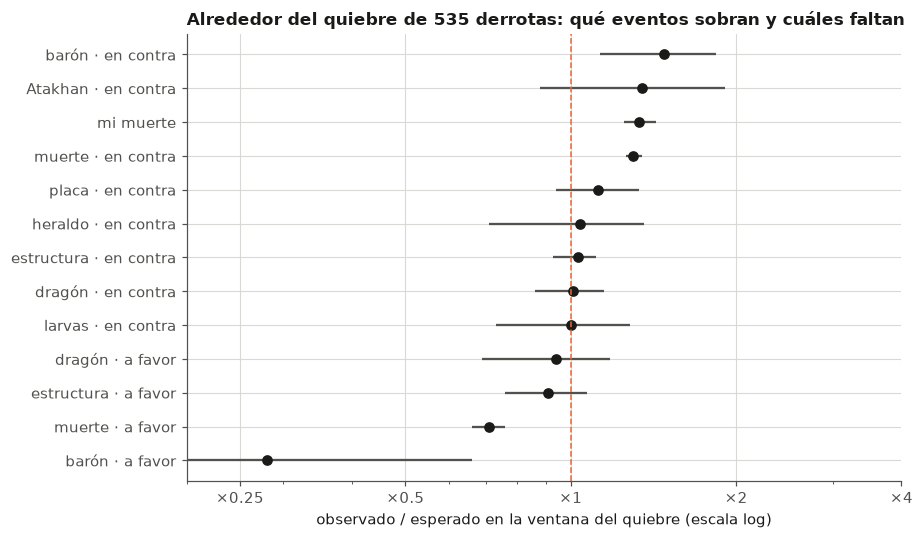

,observados,esperados,razón,lo,hi
mi muerte,394,295.6,1.33,1.25,1.43
muerte|en contra,2055,1578.3,1.30,1.26,1.35
muerte|a favor,810,1135.9,0.71,0.66,0.76
placa|en contra,527,469.3,1.12,0.94,1.33
estructura|en contra,497,484.0,1.03,0.93,1.11
estructura|a favor,137,151.0,0.91,0.76,1.07
dragón|en contra,119,118.4,1.01,0.86,1.15
larvas|en contra,81,80.7,1.00,0.73,1.28
heraldo|en contra,24,23.1,1.04,0.71,1.36
barón|en contra,51,34.4,1.48,1.13,1.84


In [10]:
# Ventana del quiebre en las derrotas: observado contra esperado para esos mismos minutos.
derrotas = q[q["gane"] == 0]
con_d2 = derrotas[derrotas["d2"].notna()]
sin_d2 = derrotas.index.difference(con_d2.index)
print(f"Derrotas: {len(derrotas)}; con quiebre D2: {len(con_d2)}; sin D2 (v nunca cruzó hacia abajo): "
      f"{len(sin_d2)}")

mis_muertes = ev[(ev["tipo"] == "CHAMPION_KILL") & (ev["victimId"] == ev["partida"].map(yo["participantId"]))]
conteo_q = conteo.copy()
mm = mis_muertes.groupby(["partida", "minuto"]).size()
conteo_q["mi muerte"] = mm.reindex(conteo_q.index).fillna(0)
CLASES_Q = ["mi muerte", "muerte|en contra", "muerte|a favor", "placa|en contra", "estructura|en contra",
            "estructura|a favor", "dragón|en contra", "larvas|en contra", "heraldo|en contra",
            "barón|en contra", "Atakhan|en contra", "dragón|a favor", "barón|a favor"]

# Rejilla partida × minuto de juego (minutos 0 .. último − 1) de todas las derrotas.
rej = pd.DataFrame([(p, m) for p, u in derrotas["ultimo"].items() for m in range(int(u))],
                   columns=["partida", "minuto"])
rej = rej.join(conteo_q[CLASES_Q], on=["partida", "minuto"]).fillna(0)
d2 = rej["partida"].map(con_d2["d2"])
rej["ventana"] = (rej["minuto"] >= d2 - 2) & (rej["minuto"] < d2 + 1)

fuera = rej[~rej["ventana"]].groupby("minuto")[CLASES_Q].mean()   # tasa esperada por minuto
dentro = rej[rej["ventana"]]
esperado_fila = fuera.reindex(dentro["minuto"]).to_numpy()

def razon(filas_idx):
    obs = dentro[CLASES_Q].to_numpy()[filas_idx].sum(axis=0)
    esp = np.nansum(esperado_fila[filas_idx], axis=0)
    return obs / esp, obs, esp

r, obs, esp = razon(np.arange(len(dentro)))
rng = np.random.default_rng(SEMILLA)
por_partida = pd.Series(np.arange(len(dentro))).groupby(dentro["partida"].to_numpy()).apply(np.array)
reps = []
for _ in range(1000):
    elegidas = rng.integers(0, len(por_partida), len(por_partida))
    reps.append(razon(np.concatenate(por_partida.iloc[elegidas].to_list()))[0])
lo, hi = np.percentile(reps, [2.5, 97.5], axis=0)
tabla_q = pd.DataFrame({"observados": obs.astype(int), "esperados": esp.round(1), "razón": r.round(2),
                        "lo": lo.round(2), "hi": hi.round(2)}, index=CLASES_Q)

orden = tabla_q.sort_values("razón").index
fig, ax = plt.subplots(figsize=(8.5, 5))
y = np.arange(len(orden))
ax.hlines(y, tabla_q.loc[orden, "lo"].clip(lower=.2), tabla_q.loc[orden, "hi"], color=SUAVE, lw=1.5)
ax.plot(tabla_q.loc[orden, "razón"], y, "o", color=TINTA)
ax.axvline(1, color=NARANJA, lw=1, ls="--")
ax.set_xscale("log")
ax.set_xlim(.2, 4)
ax.set_xticks([.25, .5, 1, 2, 4], ["×0.25", "×0.5", "×1", "×2", "×4"])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_yticks(y, [c.replace("|", " · ") for c in orden])
ax.set_xlabel("observado / esperado en la ventana del quiebre (escala log)")
ax.set_title(f"Alrededor del quiebre de {len(con_d2)} derrotas: qué eventos sobran y cuáles faltan")
plt.tight_layout()
plt.show()
tabla_q

**Lectura · el quiebre**

*Cuánto mueve cada evento* (cambio de $v$ en el minuto en que ocurre):
- **Una muerte es el evento que más oro mueve**: ±1.8 puntos de $v$ antes del minuto 15 y ±0.6 después.
  Baja con el tiempo porque el mismo oro pesa menos cuando hay más oro en el mapa.
- Después del minuto 15, el **barón** (±0.8) es el único objetivo que mueve más que una muerte; las
  estructuras mueven ±0.25 y las placas, el heraldo y las larvas casi nada.
- **El dragón tiene signo contrario**: el minuto en que mi equipo toma un dragón, $v$ *baja* (−0.55
  antes del 15). El dragón da poco oro y cuesta tiempo (mientras se pelea, el rival junta oro en
  otro lado). Su valor está en las mejoras permanentes, que esta medida no ve. Es una asociación del
  mismo minuto, no un efecto causal.

*Qué rodea al quiebre* (535 de las 537 derrotas tienen D2):
- Sobran **muertes de mi equipo** (×1.30 [1.26–1.35]) y faltan **muertes del rival** (×0.71). Esto
  es en parte **por construcción**: el quiebre se define como el minuto en que $v$ cruza hacia abajo,
  y las muertes son lo que más mueve $v$.
- Lo informativo es lo que **no** sobra: los dragones, las larvas, el heraldo y las estructuras del
  rival aparecen **lo esperado** (razones de 0.9 a 1.1). Entre los monstruos, solo el **barón del
  rival** aparece de más (×1.48 [1.13–1.84]), y el barón propio casi nunca (×0.28). Es coherente con
  H2 ("no concluyente"): el quiebre no lo marcan los objetivos en general, sino las peleas, y al
  final el barón.
- **Mis muertes** suben ×1.33 [1.25–1.43] en la ventana: lo mismo que las de todo el equipo. En el
  quiebre muero en proporción al equipo, no más.

## 3. ¿Importa el camino o solo dónde vas?

El notebook de reducción de dimensionalidad encontró que, al minuto 20, combinar los 20 minutos
predice el resultado igual que mirar solo $v(20)$. Aquí se repite la comparación **minuto a
minuto**, con modelos que sí pueden aprovechar el camino, y se mide con pérdida logarítmica.

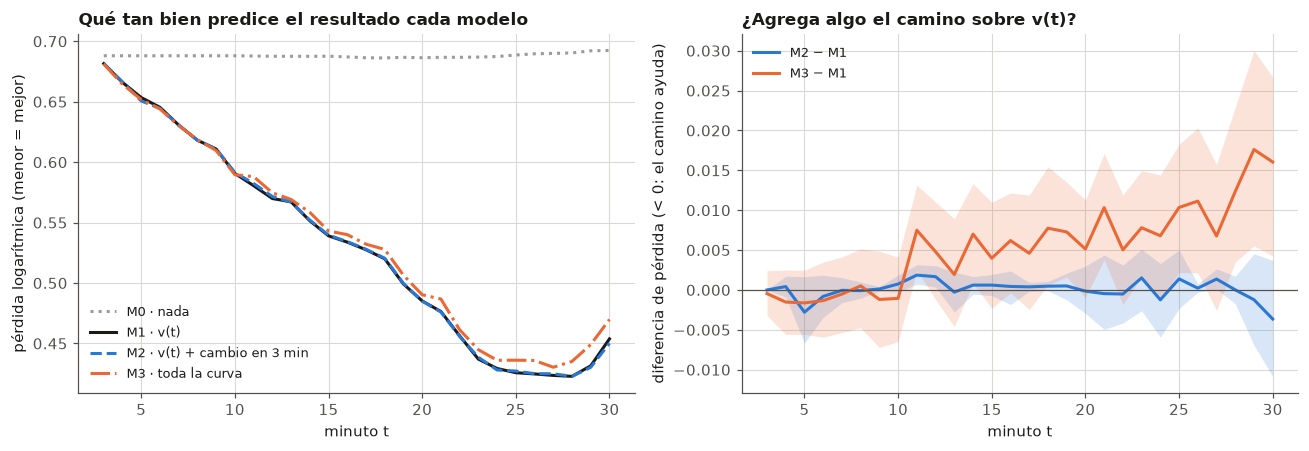

,partidas,victorias,M0,M1,M2,M3,M2 − M1,M3 − M1
minuto,,,,,,,,
5,1195,55%,0.6880,0.6535,0.6507,0.6518,-0.0028,-0.0016
10,1195,55%,0.6880,0.5907,0.5914,0.5896,0.0007,-0.0011
15,1186,55%,0.6877,0.5391,0.5397,0.5430,0.0006,0.0040
20,1118,56%,0.6864,0.4852,0.4850,0.4903,-0.0002,0.0051
25,992,55%,0.6887,0.4258,0.4272,0.4362,0.0014,0.0103


In [11]:
V = v.pivot(index="partida", columns="minuto", values="v")
y_todo = gane.loc[V.index].to_numpy()
ultimo = q.loc[V.index, "ultimo"].to_numpy()

def perdida_log(y, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))

filas, perdidas = [], {}
for t in range(3, 31):
    m = ultimo > t                                  # la partida siguió después del cuadro t
    Xt = V.loc[m, list(range(t + 1))].to_numpy()
    yt = y_todo[m]
    if len(yt) < 100 or min(yt.mean(), 1 - yt.mean()) * len(yt) < 30:
        break
    cv = StratifiedKFold(5, shuffle=True, random_state=SEMILLA)
    pred = {k: np.zeros(len(yt)) for k in ("M0", "M1", "M2", "M3")}
    for ent, pru in cv.split(Xt, yt):
        pred["M0"][pru] = yt[ent].mean()
        f1 = Xt[:, [t]]
        f2 = np.column_stack([Xt[:, t], Xt[:, t] - Xt[:, t - 3]])
        pred["M1"][pru] = LogisticRegression(C=1e6, max_iter=1000).fit(f1[ent], yt[ent]).predict_proba(f1[pru])[:, 1]
        pred["M2"][pru] = LogisticRegression(C=1e6, max_iter=1000).fit(f2[ent], yt[ent]).predict_proba(f2[pru])[:, 1]
        m3 = LogisticRegressionCV(Cs=10, cv=5, scoring="neg_log_loss", max_iter=2000)
        pred["M3"][pru] = m3.fit(Xt[ent], yt[ent]).predict_proba(Xt[pru])[:, 1]
    pl = {k: perdida_log(yt, p) for k, p in pred.items()}
    perdidas[t] = pl
    rng = np.random.default_rng(SEMILLA + t)
    idx = rng.integers(0, len(yt), (1000, len(yt)))
    dif2 = (pl["M2"] - pl["M1"])[idx].mean(axis=1)
    dif3 = (pl["M3"] - pl["M1"])[idx].mean(axis=1)
    filas.append({"minuto": t, "partidas": len(yt), "victorias": f"{yt.mean():.0%}",
                  **{k: pl[k].mean() for k in pl},
                  "M2 − M1": pl["M2"].mean() - pl["M1"].mean(),
                  "M2 − M1 lo": np.percentile(dif2, 2.5), "M2 − M1 hi": np.percentile(dif2, 97.5),
                  "M3 − M1": pl["M3"].mean() - pl["M1"].mean(),
                  "M3 − M1 lo": np.percentile(dif3, 2.5), "M3 − M1 hi": np.percentile(dif3, 97.5)})
camino = pd.DataFrame(filas).set_index("minuto")

fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.2))
for k, color, est in [("M0", "#9a9a9a", ":"), ("M1", TINTA, "-"), ("M2", AZUL, "--"), ("M3", NARANJA, "-.")]:
    a.plot(camino.index, camino[k], est, color=color, label={"M0": "M0 · nada", "M1": "M1 · v(t)",
           "M2": "M2 · v(t) + cambio en 3 min", "M3": "M3 · toda la curva"}[k])
a.set_xlabel("minuto t")
a.set_ylabel("pérdida logarítmica (menor = mejor)")
a.set_title("Qué tan bien predice el resultado cada modelo")
a.legend(fontsize=8.5)
for k, color in [("M2 − M1", AZUL), ("M3 − M1", NARANJA)]:
    b.fill_between(camino.index, camino[f"{k} lo"], camino[f"{k} hi"], color=color, alpha=.18, lw=0)
    b.plot(camino.index, camino[k], color=color, label=k)
b.axhline(0, color=SUAVE, lw=.8)
b.set_xlabel("minuto t")
b.set_ylabel("diferencia de pérdida (< 0: el camino ayuda)")
b.set_title("¿Agrega algo el camino sobre v(t)?")
b.legend(fontsize=8.5)
plt.tight_layout()
plt.show()
camino.loc[[5, 10, 15, 20, 25], ["partidas", "victorias", "M0", "M1", "M2", "M3", "M2 − M1", "M3 − M1"]].round(4)

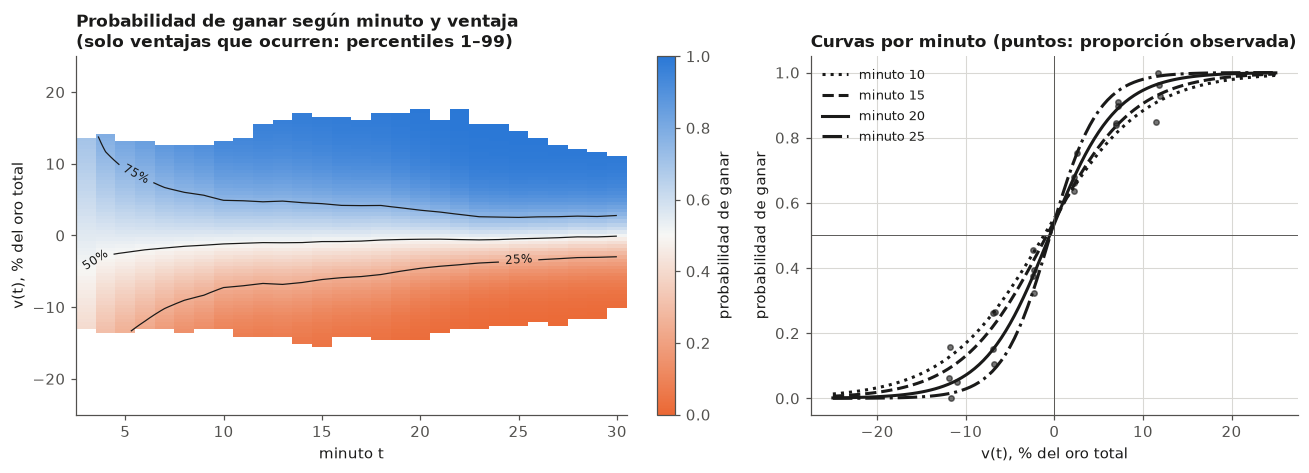

,minuto 10,minuto 15,minuto 20,minuto 25
v = −10 %,3 de 20,3 de 20,1 de 20,1 de 20
v = −5 %,7 de 20,6 de 20,5 de 20,3 de 20
v = 0,11 de 20,11 de 20,11 de 20,11 de 20
v = +5 %,15 de 20,15 de 20,16 de 20,18 de 20
v = +10 %,18 de 20,18 de 20,19 de 20,20 de 20


In [12]:
# Probabilidad de ganar según la ventaja al minuto t (regresión logística de v(t), por minuto).
rejilla_v = np.linspace(-25, 25, 101)
prob, visible = {}, {}
for t in range(3, int(camino.index.max()) + 1):
    m = ultimo > t
    modelo = LogisticRegression(C=1e6, max_iter=1000).fit(V.loc[m, [t]].to_numpy(), y_todo[m])
    prob[t] = modelo.predict_proba(rejilla_v[:, None])[:, 1]
    lo_v, hi_v = np.percentile(V.loc[m, t], [1, 99])          # sin extrapolar a ventajas que no ocurren
    visible[t] = np.where((rejilla_v >= lo_v) & (rejilla_v <= hi_v), prob[t], np.nan)
P = pd.DataFrame(prob, index=rejilla_v)
P_vis = pd.DataFrame(visible, index=rejilla_v)

cmap = LinearSegmentedColormap.from_list("res", [NARANJA, "#f7f7f5", AZUL])
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1.25, 1]})
im = a.imshow(P_vis.to_numpy(), origin="lower", aspect="auto", cmap=cmap, vmin=0, vmax=1,
              extent=[P.columns.min() - .5, P.columns.max() + .5, rejilla_v[0], rejilla_v[-1]])
a.grid(False)
cs = a.contour(P.columns, rejilla_v, P_vis.to_numpy(), levels=[.25, .5, .75], colors=TINTA, linewidths=.8)
a.clabel(cs, fmt=lambda x: f"{x:.0%}", fontsize=8)
a.set_xlabel("minuto t")
a.set_ylabel("v(t), % del oro total")
a.set_title("Probabilidad de ganar según minuto y ventaja\n(solo ventajas que ocurren: percentiles 1–99)")
fig.colorbar(im, ax=a, label="probabilidad de ganar", fraction=.046)

for t, est in [(10, ":"), (15, "--"), (20, "-"), (25, "-.")]:
    if t not in prob:
        continue
    b.plot(rejilla_v, prob[t], est, color=TINTA, label=f"minuto {t}")
    m = ultimo > t
    vt, yt = V.loc[m, t].to_numpy(), y_todo[m]
    cortes = np.arange(-25, 26, 5)
    grupo = np.digitize(vt, cortes)
    for gi in np.unique(grupo):
        sel = grupo == gi
        if sel.sum() >= 25:
            b.plot(np.median(vt[sel]), yt[sel].mean(), "o", color=TINTA, ms=3.5, alpha=.6)
b.axhline(.5, color=SUAVE, lw=.6)
b.axvline(0, color=SUAVE, lw=.6)
b.set_xlabel("v(t), % del oro total")
b.set_ylabel("probabilidad de ganar")
b.set_title("Curvas por minuto (puntos: proporción observada)")
b.legend(fontsize=8.5)
plt.tight_layout()
plt.show()

tabla_p = pd.DataFrame({t: [f"{int(round(20 * P.loc[P.index[np.argmin(abs(P.index - x))], t]))} de 20"
                            for x in (-10, -5, 0, 5, 10)] for t in (10, 15, 20, 25) if t in prob},
                       index=["v = −10 %", "v = −5 %", "v = 0", "v = +5 %", "v = +10 %"])
tabla_p.columns = [f"minuto {t}" for t in tabla_p.columns]
tabla_p

**Lectura · camino contra posición**

- **El camino no agrega nada.** El cambio de los últimos 3 minutos (M2) empata con $v(t)$ sola (M1) en
  todos los minutos: la diferencia ronda 0 y su intervalo incluye el 0. La curva completa (M3) queda
  incluso un poco **peor** después del minuto 10: con 20 o 30 variables casi repetidas, el modelo
  aprende ruido. En oro, **la partida no tiene memoria**: saber cómo llegaste a ir +5 % no cambia tu
  probabilidad respecto a cualquier otra partida que vaya +5 %.
- **La ventaja se vuelve más decisiva con el tiempo.** La pérdida logarítmica de M1 baja de 0.65 al
  minuto 5 a 0.43 al minuto 25, y las curvas de probabilidad se hacen más empinadas.
- **Tabla para leer una partida en vivo** (de cada 20 partidas, cuántas gano): ir −5 % significa
  ganar 7 de 20 al minuto 10, 6 al 15, 5 al 20 y 3 al 25; ir +5 % significa ganar 15, 15, 16 y 18. Es
  la versión continua de la curva de remontadas de H3, que miraba a todas las partidas con
  $v \le -5\,\%$ a la vez.
- Con $v = 0$ gano 11 de 20: la línea del 50 % queda un poco *debajo* de cero (−1 a −2 %), porque en
  esta muestra gano el 55 % de las partidas.

*Límite:* cada minuto usa solo las partidas que siguen en juego (992 al minuto 25), así que los
minutos tardíos describen partidas más parejas que la muestra completa.

## 4. ¿Dónde muero?

Cada punto es una de mis muertes. Mi base queda siempre abajo a la izquierda y la del rival arriba a
la derecha; la diagonal punteada es el río. La intensidad es **muertes por cada 100 minutos
jugados** en ese grupo, así que victorias y derrotas se pueden comparar aunque duren distinto.

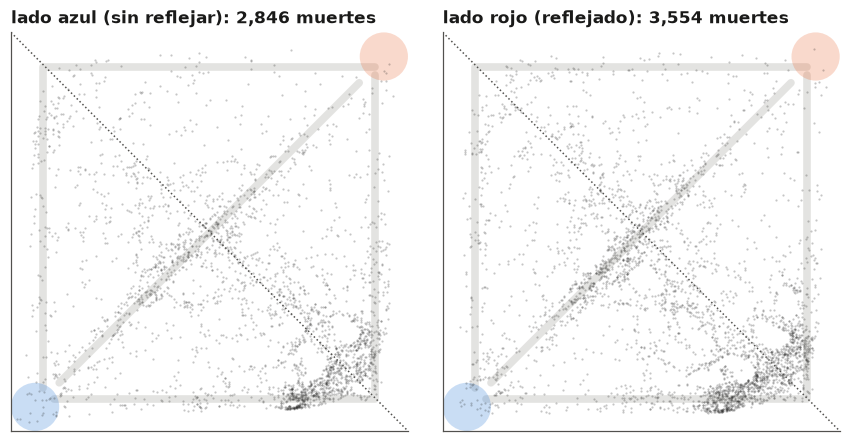

Partidas en el lado rojo: 54.8%; muertes en el lado rojo: 55.5% (la diferencia en el número de muertes es por cuántas partidas jugué de cada lado)
Centro de masa de mis muertes (lado azul / lado rojo reflejado): {'xm': 8769.0, 'ym': 5077.0} / {'xm': 8668.0, 'ym': 5042.0}


In [13]:
XMAX, YMAX = 14820, 14881

mias = ev[(ev["tipo"] == "CHAMPION_KILL") & (ev["victimId"] == ev["partida"].map(yo["participantId"]))].copy()
roja = mias["partida"].map(yo["teamId"]).to_numpy() == 200
# El mapa es simétrico respecto al río (la antidiagonal): ese reflejo cambia las bases de lugar
# pero deja cada carril en su sitio, así que BOTTOM sigue siendo la esquina inferior derecha.
mias["xm"] = np.where(roja, YMAX - mias["y"], mias["x"])
mias["ym"] = np.where(roja, XMAX - mias["x"], mias["y"])
mias["roja"] = roja
mias["gane"] = mias["partida"].map(gane).to_numpy()
mias["tarde"] = mias["ms"] / 60000 >= 15
mias["campo_rival"] = mias["xm"] / XMAX + mias["ym"] / YMAX > 1

def mapa(ax):
    '''Esquema de la Grieta: bordes, río, carril central y las dos bases.'''
    ax.set_xlim(0, XMAX); ax.set_ylim(0, YMAX); ax.set_aspect("equal")
    ax.plot([0, XMAX], [YMAX, 0], ":", color=SUAVE, lw=1)                      # río
    for xs, ys in [([1200, 1200, 13600], [1600, 13600, 13600]),               # carril superior
                   ([1600, 13600, 13600], [1200, 1200, 13300]),               # carril inferior
                   ([1800, 13000], [1800, 13000])]:                            # carril central
        ax.plot(xs, ys, color="#c9c8c4", lw=5, alpha=.5, solid_capstyle="round", zorder=0)
    ax.add_patch(plt.Circle((900, 900), 900, color=AZUL, alpha=.25, lw=0))
    ax.add_patch(plt.Circle((XMAX - 900, YMAX - 900), 900, color=NARANJA, alpha=.25, lw=0))
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)

# Comprobación del reflejo: mis muertes del lado azul y del rojo (ya reflejado) se parecen.
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, sel, titulo in [(axes[0], ~mias["roja"], "lado azul (sin reflejar)"), (axes[1], mias["roja"], "lado rojo (reflejado)")]:
    mapa(ax)
    ax.scatter(mias.loc[sel, "xm"], mias.loc[sel, "ym"], s=2, color=TINTA, alpha=.25, lw=0)
    ax.set_title(f"{titulo}: {sel.sum():,} muertes")
plt.tight_layout()
plt.show()
print(f"Partidas en el lado rojo: {(lado == 200).mean():.1%}; muertes en el lado rojo: {mias['roja'].mean():.1%} "
      "(la diferencia en el número de muertes es por cuántas partidas jugué de cada lado)")
print("Centro de masa de mis muertes (lado azul / lado rojo reflejado):",
      mias.loc[~mias["roja"], ["xm", "ym"]].mean().round(0).to_dict(), "/",
      mias.loc[mias["roja"], ["xm", "ym"]].mean().round(0).to_dict())

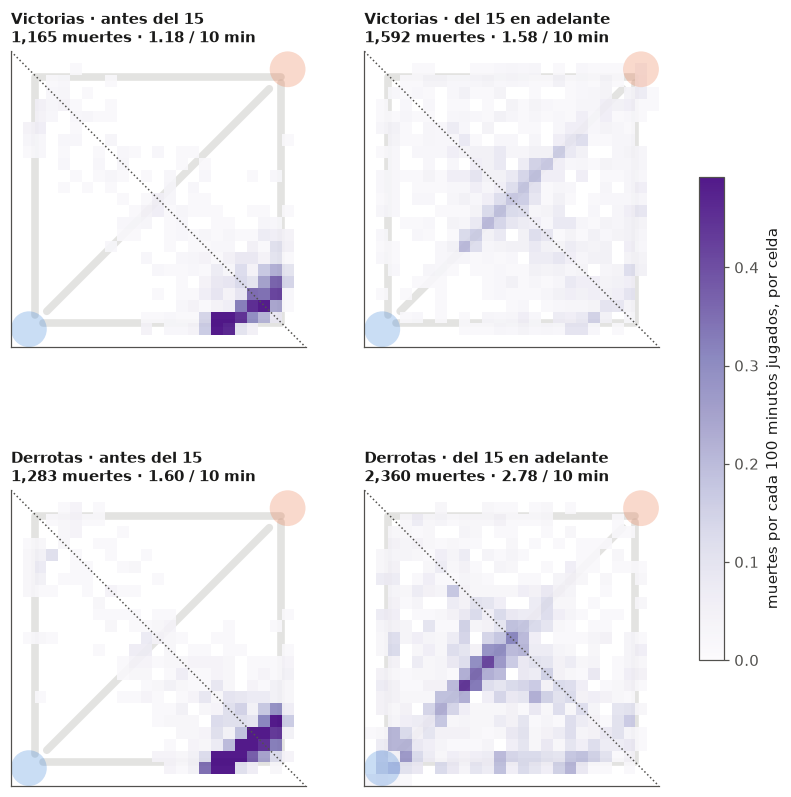

muertes  por cada 10 min en campo rival
resultado fase                                                   
Victoria  antes del 15       1165             1.18  40% [38%–43%]
          15 en adelante     1592             1.58  55% [52%–57%]
Derrota   antes del 15       1283             1.60  35% [33%–38%]
          15 en adelante     2360             2.78  26% [24%–28%]

In [14]:
dur = muestra.set_index("partida")["duracionMin"]
minutos = {(g, tarde): (np.minimum(dur, 15) if not tarde else np.maximum(dur - 15, 0))[gane == g].sum()
           for g in (1, 0) for tarde in (False, True)}
bins = [np.linspace(0, XMAX, 26), np.linspace(0, YMAX, 26)]
dens = {}
for clave, mins in minutos.items():
    sel = (mias["gane"] == clave[0]) & (mias["tarde"] == clave[1])
    h, _, _ = np.histogram2d(mias.loc[sel, "xm"], mias.loc[sel, "ym"], bins=bins)
    dens[clave] = h.T / mins * 100
tope = np.percentile(np.concatenate([d.ravel() for d in dens.values()]), 99.5)

fig, axes = plt.subplots(2, 2, figsize=(9.5, 9.5))
for (g, tarde), d in dens.items():
    ax = axes[1 - g, int(tarde)]
    mapa(ax)
    im = ax.imshow(np.where(d > 0, d, np.nan), origin="lower", extent=[0, XMAX, 0, YMAX],
                   cmap="Purples", vmin=0, vmax=tope, interpolation="nearest", alpha=.9)
    sel = (mias["gane"] == g) & (mias["tarde"] == tarde)
    ax.set_title(f"{'Victorias' if g else 'Derrotas'} · {'del 15 en adelante' if tarde else 'antes del 15'}\n"
                 f"{sel.sum():,} muertes · {sel.sum() / minutos[(g, tarde)] * 10:.2f} / 10 min",
                 fontsize=10)
fig.colorbar(im, ax=axes, shrink=.6, label="muertes por cada 100 minutos jugados, por celda")
plt.show()

filas = []
for g in (1, 0):
    for tarde in (False, True):
        sel = (mias["gane"] == g) & (mias["tarde"] == tarde)
        k_, n_ = int(mias.loc[sel, "campo_rival"].sum()), int(sel.sum())
        lo_, hi_ = e1.wilson(k_, n_)
        filas.append({"resultado": "Victoria" if g else "Derrota",
                      "fase": "15 en adelante" if tarde else "antes del 15",
                      "muertes": n_, "por cada 10 min": round(n_ / minutos[(g, tarde)] * 10, 2),
                      "en campo rival": f"{k_ / n_:.0%} [{lo_:.0%}–{hi_:.0%}]"})
pd.DataFrame(filas).set_index(["resultado", "fase"])

**Lectura · dónde muero**

- **La comprobación del reflejo sale bien:** el centro de masa de mis muertes es casi el mismo en el
  lado azul y en el rojo reflejado. (El primer intento reflejaba por el centro del mapa y mandaba el
  carril inferior a la esquina contraria; esta celda lo detectó.)
- **Antes del minuto 15, muero en mi línea**, en el tramo del carril inferior cercano al río, tanto
  al ganar como al perder. Lo que cambia es la frecuencia: **1.60 muertes por cada 10 minutos en las
  derrotas contra 1.18 en las victorias** (+36 %).
- **Del minuto 15 en adelante, la diferencia crece y cambia de lugar.** En las derrotas muero **2.78
  veces por cada 10 minutos** (contra 1.58 en las victorias) y solo el **26 %** de esas muertes ocurre
  en campo rival (contra el 55 % en las victorias). Se concentran en el carril central de **mi**
  mitad, entre el río y mi base: son muertes defendiendo, no por ir demasiado lejos.

*Cuidado con la causalidad:* cuando el equipo va perdiendo, el rival empuja y uno tiene que
defender; estas muertes son tanto causa como consecuencia de ir abajo.

## 5. Conclusiones

1. **¿Perdí yo?** Casi nunca en mi línea. En mis derrotas jugando BOTTOM, mi duelo aporta solo el
   13 % del déficit del equipo al minuto 15, y el déficit se concentra en MIDDLE (31 %). Ir arriba como equipo predice el resultado mejor que ir arriba yo.
2. **¿Qué pasa en el quiebre?** Peleas perdidas, no objetivos. Alrededor del quiebre sobran las
   muertes de mi equipo y faltan las del rival; los dragones, las larvas, el heraldo y las torres
   aparecen lo normal. El único objetivo que destaca es el barón del rival. Muero en proporción al
   resto del equipo.
3. **¿Importa el camino?** No: en oro, la partida no tiene memoria. Con la ventaja del minuto actual
   basta, y la tabla de "de cada 20" sirve para leer una partida mientras se juega.
4. **¿Dónde muero?** En las derrotas muero más (+36 % antes del 15, +76 % después) y, al final, en
   mi propia mitad, defendiendo.

**Cómo encaja con el proyecto.** El proyecto concluyó que no hay un minuto que decida mis
partidas: la puerta se va cerrando poco a poco. Este análisis agrega *qué* la cierra: peleas que mi
equipo pierde, sobre todo fuera de mi línea, y una ventaja que vale lo mismo sin importar cómo se
llegó a ella.

**Límites.** Todo esto es **exploratorio**: hice muchas comparaciones y algunas saldrán por azar.
Además, es una sola persona, son asociaciones y no efectos causales, y las muertes defendiendo son
tanto causa como consecuencia. Para la siguiente ronda, cada resultado puede convertirse en una
hipótesis registrada antes de ver datos nuevos, por ejemplo: *"en mis derrotas, MIDDLE aporta más
del déficit al minuto 15 que BOTTOM"*.